# 15. Controlled Field-only versus Mixed-domain fine-tuning

## Introduction

Does laboratory rehearsal improve field generalization when Field-only and Mixed fine-tuning receive identical Field examples and optimizer updates? Notebooks 06–08 used different Field exposure, selection schedules and, in the final geometric ResNet18 comparison, different initializations. Their observed Mixed advantage therefore did not isolate the contribution of laboratory rehearsal.

This experiment compares ResNet18 under a fixed, paired protocol using seeds 42, 43 and 44. On the historical 47-image PlantDoc Field Test, Field-only achieves mean macro-F1 **0.4300 ± 0.0075**, compared with **0.4072 ± 0.0296** for Mixed (sample SD across seeds). Field-only leads in two seeds; Mixed leads slightly in one. The result does not support a consistent Mixed advantage under this recipe.

The experiment was completed on a Tesla T4. The analysis below uses its saved Colab outputs; the original execution is [preserved separately](archive/15_controlled_field_mixed_colab_executed.ipynb). All seeds reuse the same evaluation images.

## Environment and artifacts

The recorded run is `controlled_resnet18_s42_43_44_v1`, executed with PyTorch `2.11.0+cu128` at source revision `0066ddb3a93996252a8c80591a4ac49ac6324034`. Viewing saved outputs requires no GPU. The following cells reproduce tables and figures from original prediction CSV exports without training or inference.

The original Colab notebook includes completed training outputs, configuration cells and Dev curves. The full Drive run has now been imported and audited without modifying its files. All six prediction exports match the canonical test image identities, original confusion matrices and displayed tables. Full-precision histories reproduce the selected epochs, and selected checkpoint hashes match completion records and the evaluation seal. Compact prediction exports and configuration records are [preserved with provenance](../data/results/notebook15/); detailed artifact checks are in the [execution guide](../docs/notebook15_colab_guide.md).

In [1]:
# Locate the repository locally or obtain the report sources in Colab.
from pathlib import Path
import os
import subprocess
import sys

root_override = os.environ.get("PLANT_PROJECT_ROOT")
candidates = [Path(root_override)] if root_override else [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates
                     if (p / "src/controlled_field_report.py").is_file()), None)
if PROJECT_ROOT is None and "google.colab" in sys.modules:
    REPORT_REF = "experiment/controlled-field-mixed"
    checkout = Path("/content/plant-disease-diagnosis-report15")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--quiet",
                        "https://github.com/thutrang147/plant-disease-diagnosis.git", str(checkout)], check=True)
    if subprocess.check_output(["git", "-C", str(checkout), "status", "--porcelain"], text=True).strip():
        raise RuntimeError("Report checkout has local changes; choose a fresh checkout path.")
    subprocess.run(["git", "-C", str(checkout), "fetch", "--quiet", "origin", REPORT_REF], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--quiet", "--detach", "FETCH_HEAD"], check=True)
    PROJECT_ROOT = checkout
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src/controlled_field_report.py").is_file():
    raise FileNotFoundError("Open from the updated repository or set PLANT_PROJECT_ROOT; see the Colab guide.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.controlled_field_report import (
    CLASSES, SEEDS, CONDITIONS, NAMES, COLORS, load_evidence, verify_prediction_exports,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
evidence = load_evidence(PROJECT_ROOT)
summary = evidence["summary"]
per_class = evidence["per_class"]
completed = evidence["completed"]
# Optional original CSV validation is read-only and never runs inference.
RUN = Path(os.environ.get("PLANT_CONTROLLED_RUN", str(
    PROJECT_ROOT / "outputs/controlled_field_mixed/controlled_resnet18_s42_43_44_v1")))
prediction_check = verify_prediction_exports(PROJECT_ROOT, RUN, evidence)
OUTPUT_ROOT = PROJECT_ROOT / "outputs/controlled_field_mixed/notebook15_report"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Original prediction exports reconciled: 3 seeds, 6 summaries, 30 class rows.")
print("Local Drive run:", prediction_check["status"])

Original prediction exports reconciled: 3 seeds, 6 summaries, 30 class rows.
Local Drive run: All six prediction CSVs match the preserved counts


## Experimental design

Both conditions start from the same recorded ResNet18 Lab baseline. Each epoch presents all 370 Field Adapt Train images once, with identical order and augmented tensors within each pair. Mixed adds 370 distinct Lab Train images per epoch, sampled from 5,365 available images; reuse across epochs is allowed. No settings were selected from Field Test or the previously explored external and Healthy datasets.

| Component | Field-only | Mixed |
| --- | --- | --- |
| Initialization | ResNet18 Lab baseline | Identical baseline and tensor state |
| Field examples per epoch | 370 | Same 370, order and augmented tensors |
| Field batch size | 16 | 16 |
| Objective per update | Mean Field cross-entropy | Mean Field cross-entropy + 1.0 × mean Lab cross-entropy |
| Training schedule | 2 head epochs + 6 final-block epochs | Same |
| Optimizer | AdamW, reset once at phase transition | Same |
| Learning rates / weight decay | Head 1e-4; last block 1e-5; decay 1e-4 | Same |
| BatchNorm statistics | Frozen | Frozen |
| Checkpoint selection | Shared epoch from paired Field Dev macro-F1 | Same epoch within the pair |

The shared mild crop/flip/jitter policy, 224 × 224 inputs and ImageNet normalization follow the implementation preserved at the recorded commit. There is no early stopping or phase rewind. The Lab-loss weight is fixed at 1.0; the Field loss retains the same coefficient in both conditions. Mixed receives additional information and computation, so this is an exposure- and update-matched comparison rather than a compute-matched one.

Field Dev contains 92 images and selects checkpoints. Field Test contains 47 images: 8 Healthy, 9 Early Blight, 10 Late Blight, 9 Bacterial Spot and 11 Septoria Leaf Spot. Label order and split membership follow the canonical manifests. The existing row/group exclusions and exact/pHash screen reduce detectable overlap, but do not establish physical-plant independence or eliminate pretraining overlap.

## Training and validation

All three pairs completed eight epochs: **2,960 Field presentations and 192 optimizer updates per condition**, with **2,960 additional Lab presentations for Mixed**. Each epoch has 24 updates, including a final batch of two Field images. Both conditions use the same augmented Field tensor before their respective updates.

Selection maximizes the mean of the pair's five-class Field Dev macro-F1 over epochs 0–8, choosing the earliest tie. The saved validation output reports a common epoch of 8, 7 and 8 for seeds 42, 43 and 44. Evaluation follows validation and checkpoint sealing. The imported artifacts confirm identical recorded initialization, eight presentations of every Field row, matching Field tensor hashes and update counts in every batch, and the predetermined shared selection from full-precision histories. The six selected checkpoint hashes also match the original evaluation seal. These checks support consistency of the recorded protocol; they do not establish the absence of undocumented human inspection.

In [3]:
training_table = completed.rename(columns={
    "seed": "Seed", "field_presentations_per_condition": "Full Field presentations",
    "optimizer_updates_per_condition": "Full updates", "selected_common_epoch": "Selected epoch",
    "selected_field_presentations_per_condition": "Selected Field presentations",
    "selected_updates_per_condition": "Selected updates",
})
display(training_table.set_index("Seed"))

,Full Field presentations,Full updates,Selected epoch,Selected Field presentations,Selected updates
Seed,,,,,
42,2960,192,8,2960,192
43,2960,192,7,2590,168
44,2960,192,8,2960,192


Counts in this table apply to each condition. Seed 43's evaluated checkpoints have **2,590 Field presentations and 168 updates**, whereas its full run still completed 2,960 and 192. Exposure and update counts match within every evaluated pair. The two conditions share the selected epoch, so their selection is coupled rather than independent.

## Experimental results

Accuracy and macro-F1 use the fixed five-class mapping on the same 47 Field Test images for every run. Metrics are recalculated from the original image-level prediction CSV exports and agree with all original confusion counts and displayed scores. Standard deviations below use `ddof=1`; they describe optimization variability across three seeds, not uncertainty across independent test datasets.

In [4]:
seed_table = summary.assign(
    Condition=summary.condition.map(NAMES),
    **{"Correct / 47": summary.correct.astype(str) + "/" + summary.n.astype(str)},
).rename(columns={"seed": "Seed", "accuracy": "Accuracy", "macro_f1": "Macro-F1"})
display(seed_table[["Seed", "Condition", "Correct / 47", "Accuracy", "Macro-F1"]]
        .set_index(["Seed", "Condition"]).round(4))

Correct / 47  Accuracy  Macro-F1
Seed Condition                                  
42   Field-only        22/47    0.4681    0.4338
     Mixed             21/47    0.4468    0.3970
43   Field-only        21/47    0.4468    0.4214
     Mixed             20/47    0.4255    0.3840
44   Field-only        22/47    0.4681    0.4349
     Mixed             22/47    0.4681    0.4405

### Macro-F1 by seed

The paired comparison retains all declared seeds. The annotations show Mixed minus Field-only macro-F1; seed identity is shared across the two conditions.

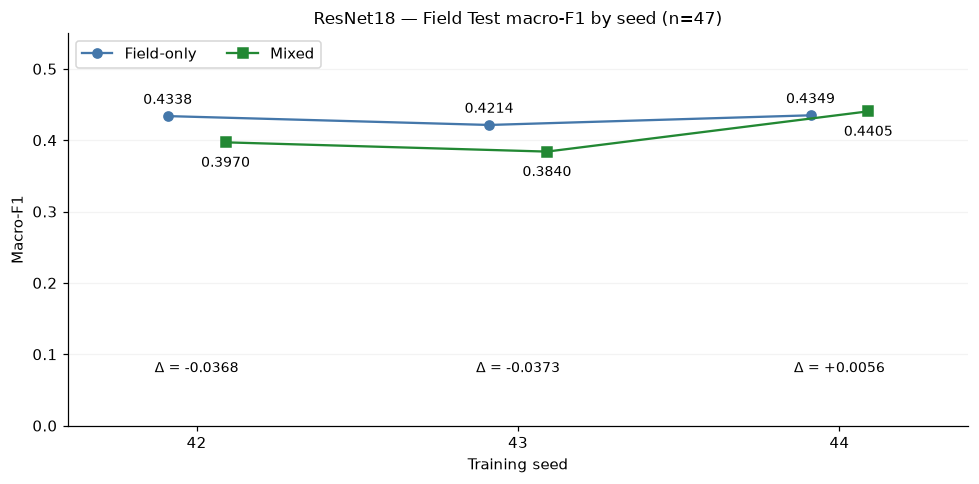

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(SEEDS))
for condition, offset, marker in [("field_only", -.09, "o"), ("mixed", .09, "s")]:
    values = summary[summary.condition.eq(condition)].set_index("seed").loc[list(SEEDS), "macro_f1"]
    ax.plot(x + offset, values, color=COLORS[condition], marker=marker,
            linewidth=1.5, label=NAMES[condition])
    for xx, value in zip(x + offset, values):
        ax.annotate(f"{value:.4f}", (xx, value), xytext=(0, 8 if condition == "field_only" else -16),
                    textcoords="offset points", ha="center", fontsize=9)
for i, delta in enumerate(evidence["delta"].macro_f1):
    ax.text(i, .075, f"Δ = {delta:+.4f}", ha="center", fontsize=9)
ax.set(xticks=x, xticklabels=[str(s) for s in SEEDS], xlabel="Training seed",
       ylabel="Macro-F1", ylim=(0, .55), xlim=(-.4, 2.4),
       title="ResNet18 — Field Test macro-F1 by seed (n=47)")
ax.grid(axis="y", alpha=.15)
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "field_test_macro_f1_by_seed.png", dpi=160)
plt.show()
plt.close(fig)

Field-only leads by 0.0368 and 0.0373 macro-F1 in seeds 42 and 43. Mixed leads by 0.0056 in seed 44, where accuracy is tied at 22/47. The direction of the macro-F1 difference is therefore **not consistent across all seeds**. Accuracy favors Field-only in two seeds and ties in the third.

### Mean performance and seed variation

Means and sample standard deviations summarize the same three paired runs. The final row reports the mean and SD of the within-seed Mixed minus Field-only differences, calculated before rounding.

,Accuracy mean,Accuracy SD,Macro-F1 mean,Macro-F1 SD
Condition,,,,
Field-only,0.4610,0.0123,0.4300,0.0075
Mixed,0.4468,0.0213,0.4072,0.0296
Mixed − Field-only,-0.0142,0.0123,-0.0228,0.0246


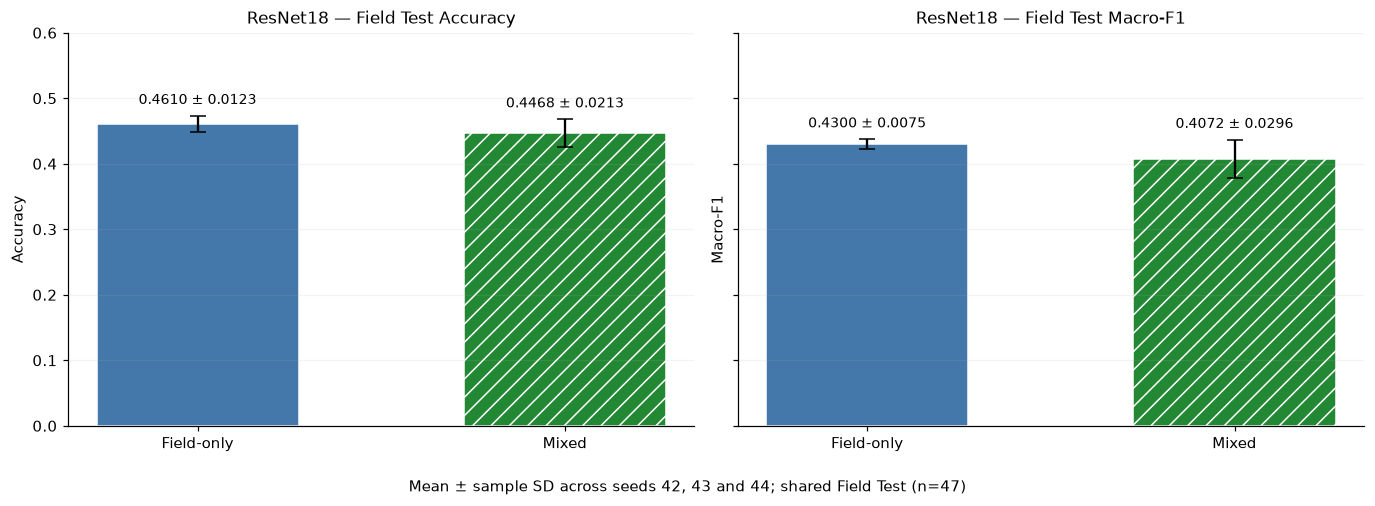

In [6]:
aggregate = evidence["aggregate"]
mean_table = pd.DataFrame({
    "Condition": [NAMES[c] for c in CONDITIONS],
    "Accuracy mean": [aggregate.loc[c, ("accuracy", "mean")] for c in CONDITIONS],
    "Accuracy SD": [aggregate.loc[c, ("accuracy", "std")] for c in CONDITIONS],
    "Macro-F1 mean": [aggregate.loc[c, ("macro_f1", "mean")] for c in CONDITIONS],
    "Macro-F1 SD": [aggregate.loc[c, ("macro_f1", "std")] for c in CONDITIONS],
}).set_index("Condition")
d = evidence["delta"]
mean_table.loc["Mixed − Field-only"] = [d.accuracy.mean(), d.accuracy.std(ddof=1),
                                       d.macro_f1.mean(), d.macro_f1.std(ddof=1)]
display(mean_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6), sharey=True)
for ax, metric, label in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro-F1"]):
    for i, condition in enumerate(CONDITIONS):
        mean = aggregate.loc[condition, (metric, "mean")]
        sd = aggregate.loc[condition, (metric, "std")]
        ax.bar(i, mean, yerr=sd, capsize=5, width=.55, color=COLORS[condition],
               edgecolor="white", hatch="" if condition == "field_only" else "//")
        ax.text(i, mean + sd + .018, f"{mean:.4f} ± {sd:.4f}", ha="center", fontsize=9)
    ax.set(xticks=range(2), xticklabels=[NAMES[c] for c in CONDITIONS],
           ylim=(0, .60), ylabel=label, title=f"ResNet18 — Field Test {label}")
    ax.grid(axis="y", alpha=.15)
fig.supxlabel("Mean ± sample SD across seeds 42, 43 and 44; shared Field Test (n=47)", fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "field_test_mean_performance.png", dpi=160)
plt.show()
plt.close(fig)

Field-only has higher mean accuracy (**0.4610 versus 0.4468**) and macro-F1 (**0.4300 versus 0.4072**). The mean paired Mixed change is **−0.0142 accuracy** (−1.42 percentage points) and **−0.0228 macro-F1**. Mixed also has greater observed macro-F1 variation (SD 0.0296 versus 0.0075), but three runs are insufficient to establish a general stability ranking. Error bars show seed SD, not confidence intervals; no statistical significance is claimed.

## Per-class performance

Correct/total counts retain the small class denominators. Each column evaluates the same class images; repeated seed counts are not new observations. Class means average the three within-seed recalls.

In [7]:
count_table = per_class.assign(
    Run=per_class.condition.map(NAMES) + " · " + per_class.seed.astype(str),
    Count=per_class.correct.astype(int).astype(str) + "/" + per_class.support.astype(int).astype(str),
).pivot(index="class_name", columns="Run", values="Count")
count_table = count_table.reindex(index=CLASSES, columns=[f"{NAMES[c]} · {s}" for c in CONDITIONS for s in SEEDS])
count_table.index.name = "Class"
count_table.columns.name = None
display(count_table)

class_means = per_class.groupby(["class_name", "condition"]).recall.mean().unstack().reindex(CLASSES)
class_table = class_means.rename(columns=NAMES).copy()
class_table["Mixed − Field-only (pp)"] = 100 * (class_means.mixed - class_means.field_only)
class_table.index.name = "Class"
class_table.columns.name = None
class_table["Mixed − Field-only (pp)"] = class_table["Mixed − Field-only (pp)"].map("{:+.2f}".format)
display(class_table.round(4))

,Field-only · 42,Field-only · 43,Field-only · 44,Mixed · 42,Mixed · 43,Mixed · 44
Class,,,,,,
Healthy,3/8,3/8,3/8,2/8,2/8,3/8
Early Blight,1/9,2/9,2/9,2/9,2/9,3/9
Late Blight,8/10,7/10,8/10,8/10,7/10,7/10
Bacterial Spot,2/9,1/9,1/9,1/9,1/9,1/9
Septoria Leaf Spot,8/11,8/11,8/11,8/11,8/11,8/11


,Field-only,Mixed,Mixed − Field-only (pp)
Class,,,
Healthy,0.3750,0.2917,-8.33
Early Blight,0.1852,0.2593,+7.41
Late Blight,0.7667,0.7333,-3.33
Bacterial Spot,0.1481,0.1111,-3.70
Septoria Leaf Spot,0.7273,0.7273,+0.00


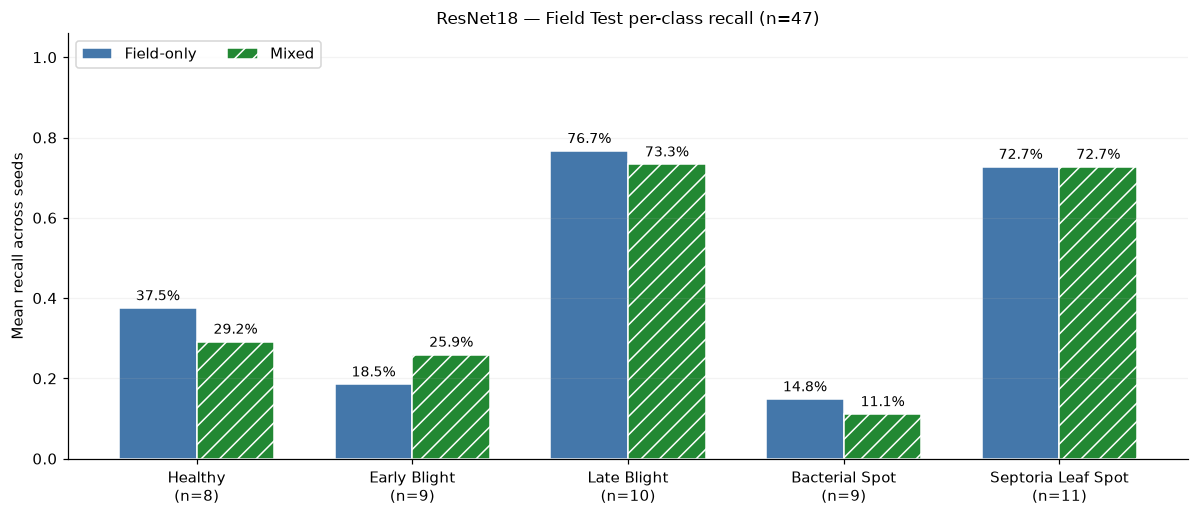

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(CLASSES))
for condition, offset in [("field_only", -.18), ("mixed", .18)]:
    values = class_means[condition].to_numpy()
    bars = ax.bar(x + offset, values, width=.36, color=COLORS[condition], label=NAMES[condition],
                  hatch="" if condition == "field_only" else "//", edgecolor="white")
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=3, fontsize=9)
ax.set(xticks=x, xticklabels=["Healthy\n(n=8)", "Early Blight\n(n=9)", "Late Blight\n(n=10)",
                             "Bacterial Spot\n(n=9)", "Septoria Leaf Spot\n(n=11)"],
       ylabel="Mean recall across seeds", ylim=(0, 1.06),
       title="ResNet18 — Field Test per-class recall (n=47)")
ax.grid(axis="y", alpha=.15)
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "field_test_per_class_recall.png", dpi=160)
plt.show()
plt.close(fig)

Mixed raises mean **Early Blight** recall from **0.1852 to 0.2593**: correct counts change from 1/9 to 2/9 in seed 42, remain 2/9 in seed 43, and rise from 2/9 to 3/9 in seed 44. This modest gain appears in two seeds and is tied in one; it is not a uniform per-seed improvement.

**Healthy** recall falls from **0.3750 to 0.2917**. Field-only recognizes 3/8 in every seed, whereas Mixed recognizes 2/8, 2/8 and 3/8. Laboratory rehearsal therefore does not preserve Healthy recognition relative to the matched Field-only condition in this experiment.

**Bacterial Spot** recall falls from **0.1481 to 0.1111** on average: Field-only recognizes 2/9, 1/9 and 1/9; Mixed recognizes 1/9 in every seed. Late Blight falls from 0.7667 to 0.7333, while Septoria Leaf Spot remains 8/11 (0.7273) in all six evaluations. These Field Test trade-offs differ from the historical external Healthy gains and Early Blight losses; they concern different models, comparisons and image sources.

### Confusion matrices

Each matrix contains 47 predictions, with true classes in rows and predicted classes in columns. All panels use the same label order and color scale; integer annotations show image counts. The six matrices are shown without pooling repeated predictions across seeds.

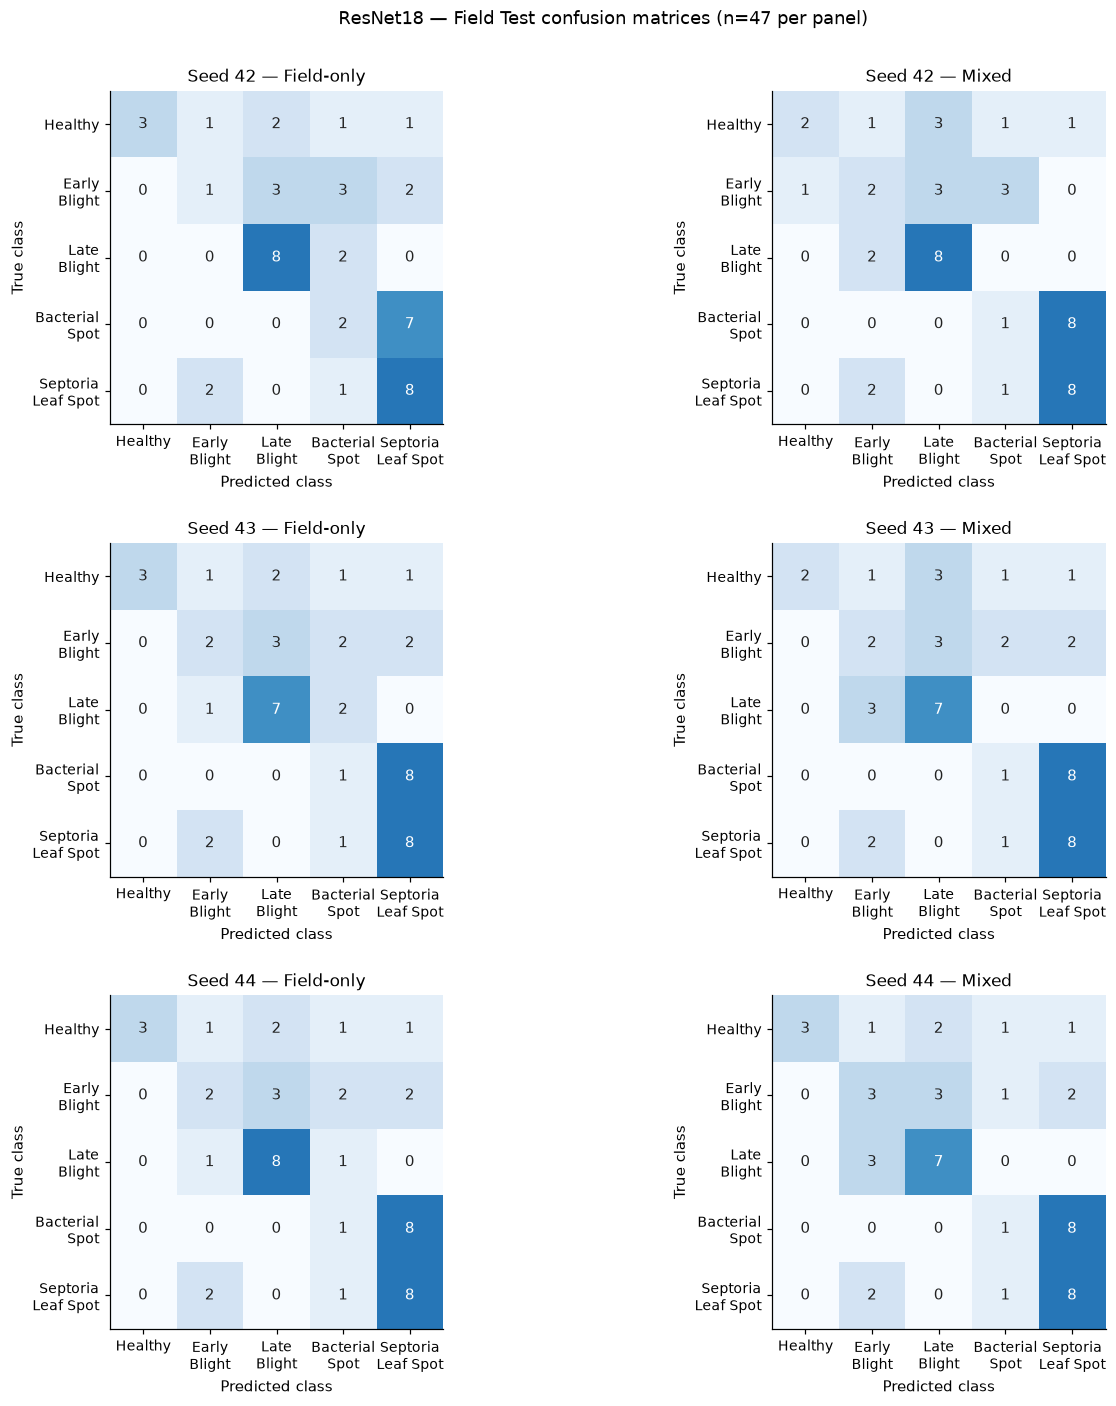

In [9]:
labels = ["Healthy", "Early\nBlight", "Late\nBlight", "Bacterial\nSpot", "Septoria\nLeaf Spot"]
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for row, seed in enumerate(SEEDS):
    for col, condition in enumerate(CONDITIONS):
        matrix = evidence["matrices"][seed, condition]
        ax = axes[row, col]
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=11)
        for i in range(5):
            for j in range(5):
                ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=10,
                        color="white" if matrix[i, j] > 5.5 else "#222222")
        ax.set(xticks=range(5), yticks=range(5), xticklabels=labels, yticklabels=labels,
               xlabel="Predicted class", ylabel="True class",
               title=f"Seed {seed} — {NAMES[condition]}")
        ax.tick_params(axis="both", labelsize=9)
fig.suptitle("ResNet18 — Field Test confusion matrices (n=47 per panel)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .975), h_pad=2)
fig.savefig(OUTPUT_ROOT / "field_test_confusion_matrices.png", dpi=160)
plt.show()
plt.close(fig)

Bacterial Spot is predominantly predicted as Septoria Leaf Spot: 7 of 9 images in the Field-only seed-42 matrix and 8 of 9 in every other matrix. Early Blight is often assigned Late Blight (3/9 in every run) or Bacterial Spot (1–3/9). These recurring destinations identify class confusion; the counts alone do not establish a biological or visual mechanism.

## Discussion

The historical Mixed advantage is not consistently reproduced under this controlled ResNet18 protocol. Field-only leads on mean Field Test accuracy and macro-F1, although Mixed has a small macro-F1 advantage in seed 44 and modestly improves Early Blight recall. Healthy and Bacterial Spot do not benefit relative to the matched Field-only models.

This result does not invalidate Notebooks 01–14. Their comparisons used different Field exposure, training schedules, checkpoint selection and, for the final geometric ResNet18 contrast, initialization. They also emphasized Field Dev and external samples rather than this controlled three-seed Field Test comparison. The new experiment removes several confounds but does not identify which historical difference caused the earlier outcome. No laboratory-retention evaluation was performed for these controlled checkpoints, so source-retention benefits cannot be inferred here.

The evidence is specific to ResNet18, a fixed Lab-loss weight of 1.0 and the recorded head/final-block recipe. Mixed adds Lab data and computation, while shared-epoch selection couples the two conditions. Three seeds share the same small, imbalanced and previously inspected Field Test; they are not three independent test datasets. Correlated images, imperfect duplicate screening and unresolved pretraining overlap further limit generalization. External v1, External v2 and Healthy v2 were already explored and were not used to retrospectively optimize this experiment. ViT-Small remains a separate possible investigation, with no new run performed here.

## Conclusion

Under the matched ResNet18 protocol, Field-only achieves the stronger mean result: **0.4610 accuracy and 0.4300 macro-F1**, versus **0.4468 and 0.4072** for Mixed. Field-only wins macro-F1 in two of three seeds. Mixed's small Early Blight recall gain accompanies lower Healthy recall and no Bacterial Spot improvement.

The completed experiment therefore provides **no consistent evidence of a Mixed advantage under this recipe**. It does not establish that mixed-domain learning is universally inferior, nor statistical superiority of Field-only. Stronger generalization claims require a new prospective grouped evaluation and a separately declared experimental scope.

## Reproducibility record

The [original executed Colab notebook](archive/15_controlled_field_mixed_colab_executed.ipynb) is preserved byte-for-byte, including all setup cells, training logs, Dev curves, saved outputs and experiment parameters. Its full SHA-256 and the recorded training source/baseline hashes are in [the evidence provenance](../data/results/notebook15/provenance.json). The [training implementation](../src/controlled_field_mixed.py) is unchanged from the recorded source commit. The [original prediction exports](../data/results/notebook15/prediction_exports/) now supply the report metrics. The earlier [transcribed notebook counts](../data/results/notebook15/confusion_counts_from_notebook.csv) remain a cross-check, with their distinct provenance preserved.

The original Drive run is imported under `outputs/controlled_field_mixed/controlled_resnet18_s42_43_44_v1/`, including configuration, environment, smoke evidence, per-seed histories, exposure/audit CSVs, completion records, selected/resume checkpoints, evaluation seal, predictions and findings. A read-only audit reconciles all 53 file hashes before and after verification, recomputes metrics, validates canonical identities and probability records, checks full-precision selection, and verifies six selected checkpoint hashes and their baseline metadata. Its [audit record](../data/results/notebook15/imported_artifact_audit.json) and the [execution guide](../docs/notebook15_colab_guide.md) document the checks. Original artifacts remain unchanged; no training or inference was repeated.

Figures generated here are written only to `outputs/controlled_field_mixed/notebook15_report/`. No training, checkpoint selection, test inference or ViT-Small extension is executed by this report.